# Supplementary analysis

In [15]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

predictions_path = Path("../results/Fe_d6/predictions.csv")
metrics_path = Path("../results/Fe_d6/metrics.json")

df = pd.read_csv(predictions_path)

with open(
    metrics_path,
    "r",
    encoding="utf-8",
) as handle:
    metrics = json.load(handle)

print("Predictions file:", predictions_path)
print("Metrics file    :", metrics_path)

print(
    "Prediction pairs:",
    len(df)
)

print(
    "Columns:",
    list(df.columns)
)

expected_count = int(
    metrics["prediction_count"]
)

if len(df) != expected_count:
    raise RuntimeError(
        "Prediction count mismatch: "
        f"predictions.csv contains {len(df)} rows, "
        f"metrics.json reports {expected_count}"
    )

required_columns = {
    "sz_true",
    "sz_pred",
    "lz_true",
    "lz_pred",
}

missing = (
    required_columns
    - set(df.columns)
)

if missing:
    raise ValueError(
        f"Missing columns: {sorted(missing)}"
    )

print(
    f"Fe test samples: {len(df)}"
)

for target in (
    "sz",
    "lz",
):
    y_true = df[
        f"{target}_true"
    ].to_numpy(
        dtype=float
    )

    y_pred = df[
        f"{target}_pred"
    ].to_numpy(
        dtype=float
    )

    residual = (
        y_pred
        - y_true
    )

    sse = np.sum(
        residual ** 2
    )

    sst = np.sum(
        (
            y_true
            - np.mean(
                y_true
            )
        ) ** 2
    )

    rmse = np.sqrt(
        np.mean(
            residual ** 2
        )
    )

    r2 = (
        1.0
        - sse / sst
    )

    print()
    print(
        target.upper()
    )

    print(
        f"  N                    = {len(y_true)}"
    )

    print(
        f"  target minimum       = {np.min(y_true):.8f}"
    )

    print(
        f"  target maximum       = {np.max(y_true):.8f}"
    )

    print(
        f"  target range         = {np.ptp(y_true):.8f}"
    )

    print(
        f"  target mean          = {np.mean(y_true):.8f}"
    )

    print(
        f"  target population SD = {np.std(y_true, ddof=0):.8f}"
    )

    print(
        f"  prediction minimum   = {np.min(y_pred):.8f}"
    )

    print(
        f"  prediction maximum   = {np.max(y_pred):.8f}"
    )

    print(
        f"  RMSE                 = {rmse:.8f}"
    )

    print(
        f"  R2                   = {r2:.8f}"
    )

Predictions file: ../results/Fe_d6/predictions.csv
Metrics file    : ../results/Fe_d6/metrics.json
Prediction pairs: 567
Columns: ['sample_id', 'prefix', 'subset', 'b_ext_t', 'sz_true_standardized', 'sz_pred_standardized', 'sz_true', 'sz_pred', 'sz_residual', 'lz_true_standardized', 'lz_pred_standardized', 'lz_true', 'lz_pred', 'lz_residual', 'Prefix', 'NElectrons_3d', 'TEN_DQ', 'SlaterScale', 'SOC_2p', 'SOC_3d', 'H_ex', 'B_ext_T', 'Sz', 'Lz', 'S2', 'L2', 'J2', 'source_index', 'source_row_position', 'system', 'element', 'n_electrons_3d', 'sz_label', 'lz_label', 'expected_b_ext_t', 'external_field_direction_x', 'external_field_direction_y', 'external_field_direction_z', 'xas_file', 'xmcd_file', 'xas_rows', 'xmcd_rows', 'xas_removed_nonfinite_rows', 'xmcd_removed_nonfinite_rows', 'feature_count']
Fe test samples: 567

SZ
  N                    = 567
  target minimum       = -1.79210000
  target maximum       = -0.46680700
  target range         = 1.32529300
  target mean          = -1.49

In [16]:
from pathlib import Path
import json

import numpy as np
import pandas as pd


# ============================================================
# Input files
# ============================================================

predictions_path = Path(
    "../results/Co_d7/predictions.csv"
)

metrics_path = Path(
    "../results/Co_d7/metrics.json"
)


# ============================================================
# Load predictions
# ============================================================

if not predictions_path.is_file():
    raise FileNotFoundError(
        "Predictions file was not found: "
        f"{predictions_path}"
    )

df = pd.read_csv(
    predictions_path
)


# ============================================================
# Load metrics
# ============================================================

if not metrics_path.is_file():
    raise FileNotFoundError(
        "Metrics file was not found: "
        f"{metrics_path}"
    )

with metrics_path.open(
    "r",
    encoding="utf-8",
) as handle:
    metrics = json.load(
        handle
    )


# ============================================================
# Basic report
# ============================================================

print(
    "Predictions file:",
    predictions_path,
)

print(
    "Metrics file    :",
    metrics_path,
)

print(
    "Prediction pairs:",
    len(
        df
    ),
)

print(
    "Columns:",
    list(
        df.columns
    ),
)


# ============================================================
# Validate prediction count
# ============================================================

if "prediction_count" not in metrics:
    raise KeyError(
        "metrics.json does not contain prediction_count"
    )

expected_count = int(
    metrics[
        "prediction_count"
    ]
)

if len(
    df
) != expected_count:
    raise RuntimeError(
        "Prediction-count mismatch: "
        f"predictions.csv contains {len(df)} rows, "
        f"but metrics.json reports {expected_count}"
    )


# ============================================================
# Validate required columns
# ============================================================

required_columns = {
    "sample_id",
    "sz_true",
    "sz_pred",
    "lz_true",
    "lz_pred",
}

missing_columns = (
    required_columns
    - set(
        df.columns
    )
)

if missing_columns:
    raise ValueError(
        "Missing columns: "
        f"{sorted(missing_columns)}"
    )


# ============================================================
# Validate sample IDs
# ============================================================

if df[
    "sample_id"
].duplicated().any():
    duplicate_count = int(
        df[
            "sample_id"
        ].duplicated().sum()
    )

    raise RuntimeError(
        "predictions.csv contains duplicate sample IDs: "
        f"{duplicate_count}"
    )


# ============================================================
# Validate numeric values
# ============================================================

numeric_columns = (
    "sz_true",
    "sz_pred",
    "lz_true",
    "lz_pred",
)

for column in numeric_columns:
    values = pd.to_numeric(
        df[
            column
        ],
        errors="coerce",
    ).to_numpy(
        dtype=np.float64
    )

    if not np.isfinite(
        values
    ).all():
        raise ValueError(
            f"{column} contains NaN or Inf"
        )


print(
    "Prediction-count validation passed."
)

print(
    f"Co test samples: {len(df)}"
)


# ============================================================
# Calculate and report metrics
# ============================================================

for target in (
    "sz",
    "lz",
):
    y_true = df[
        f"{target}_true"
    ].to_numpy(
        dtype=np.float64
    )

    y_pred = df[
        f"{target}_pred"
    ].to_numpy(
        dtype=np.float64
    )

    residual = (
        y_pred
        - y_true
    )

    sse = float(
        np.sum(
            residual ** 2
        )
    )

    true_mean = float(
        np.mean(
            y_true
        )
    )

    sst = float(
        np.sum(
            (
                y_true
                - true_mean
            ) ** 2
        )
    )

    mse = float(
        np.mean(
            residual ** 2
        )
    )

    rmse = float(
        np.sqrt(
            mse
        )
    )

    target_standard_deviation = float(
        np.std(
            y_true,
            ddof=0,
        )
    )

    if sst > 0.0:
        r2 = float(
            1.0
            - sse / sst
        )

    else:
        r2 = None

    if target_standard_deviation > 0.0:
        nrmse = float(
            rmse
            / target_standard_deviation
        )

    else:
        nrmse = None

    print()

    print(
        target.upper()
    )

    print(
        f"  N                    = {len(y_true)}"
    )

    print(
        f"  target minimum       = {np.min(y_true):.8f}"
    )

    print(
        f"  target maximum       = {np.max(y_true):.8f}"
    )

    print(
        f"  target range         = {np.ptp(y_true):.8f}"
    )

    print(
        f"  target mean          = {true_mean:.8f}"
    )

    print(
        "  target population SD = "
        f"{target_standard_deviation:.8f}"
    )

    print(
        f"  prediction minimum   = {np.min(y_pred):.8f}"
    )

    print(
        f"  prediction maximum   = {np.max(y_pred):.8f}"
    )

    print(
        f"  residual minimum     = {np.min(residual):.8f}"
    )

    print(
        f"  residual maximum     = {np.max(residual):.8f}"
    )

    print(
        f"  SSE                  = {sse:.8f}"
    )

    print(
        f"  SST                  = {sst:.8f}"
    )

    print(
        f"  MSE                  = {mse:.8f}"
    )

    print(
        f"  RMSE                 = {rmse:.8f}"
    )

    if nrmse is None:
        print(
            "  NRMSE                = undefined"
        )

    else:
        print(
            f"  NRMSE                = {nrmse:.8f}"
        )

    if r2 is None:
        print(
            "  R2                   = undefined"
        )

    else:
        print(
            f"  R2                   = {r2:.8f}"
        )

Predictions file: ../results/Co_d7/predictions.csv
Metrics file    : ../results/Co_d7/metrics.json
Prediction pairs: 567
Columns: ['sample_id', 'prefix', 'subset', 'b_ext_t', 'sz_true_standardized', 'sz_pred_standardized', 'sz_true', 'sz_pred', 'sz_residual', 'lz_true_standardized', 'lz_pred_standardized', 'lz_true', 'lz_pred', 'lz_residual', 'Prefix', 'NElectrons_3d', 'TEN_DQ', 'SlaterScale', 'SOC_2p', 'SOC_3d', 'H_ex', 'B_ext_T', 'Sz', 'Lz', 'S2', 'L2', 'J2', 'source_index', 'source_row_position', 'system', 'element', 'n_electrons_3d', 'sz_label', 'lz_label', 'expected_b_ext_t', 'external_field_direction_x', 'external_field_direction_y', 'external_field_direction_z', 'xas_file', 'xmcd_file', 'xas_rows', 'xmcd_rows', 'xas_removed_nonfinite_rows', 'xmcd_removed_nonfinite_rows', 'feature_count']
Prediction-count validation passed.
Co test samples: 567

SZ
  N                    = 567
  target minimum       = -1.12002000
  target maximum       = -0.24644800
  target range         = 0.873

In [17]:
from pathlib import Path
import json

import numpy as np
import pandas as pd


# ============================================================
# Input files
# ============================================================

predictions_path = Path(
    "../results/Ni_d8/predictions.csv"
)

metrics_path = Path(
    "../results/Ni_d8/metrics.json"
)


# ============================================================
# Load predictions
# ============================================================

if not predictions_path.is_file():
    raise FileNotFoundError(
        "Predictions file was not found: "
        f"{predictions_path}"
    )

df = pd.read_csv(
    predictions_path
)


# ============================================================
# Load metrics
# ============================================================

if not metrics_path.is_file():
    raise FileNotFoundError(
        "Metrics file was not found: "
        f"{metrics_path}"
    )

with metrics_path.open(
    "r",
    encoding="utf-8",
) as handle:
    metrics = json.load(
        handle
    )


# ============================================================
# Basic report
# ============================================================

print(
    "Predictions file:",
    predictions_path,
)

print(
    "Metrics file    :",
    metrics_path,
)

print(
    "Prediction pairs:",
    len(
        df
    ),
)

print(
    "Columns:",
    list(
        df.columns
    ),
)


# ============================================================
# Validate prediction count
# ============================================================

if "prediction_count" not in metrics:
    raise KeyError(
        "metrics.json does not contain prediction_count"
    )

expected_count = int(
    metrics[
        "prediction_count"
    ]
)

if len(
    df
) != expected_count:
    raise RuntimeError(
        "Prediction-count mismatch: "
        f"predictions.csv contains {len(df)} rows, "
        f"but metrics.json reports {expected_count}"
    )


# ============================================================
# Validate required columns
# ============================================================

required_columns = {
    "sample_id",
    "sz_true",
    "sz_pred",
    "lz_true",
    "lz_pred",
}

missing_columns = (
    required_columns
    - set(
        df.columns
    )
)

if missing_columns:
    raise ValueError(
        "Missing columns: "
        f"{sorted(missing_columns)}"
    )


# ============================================================
# Validate sample IDs
# ============================================================

if df[
    "sample_id"
].duplicated().any():
    duplicate_count = int(
        df[
            "sample_id"
        ].duplicated().sum()
    )

    raise RuntimeError(
        "predictions.csv contains duplicate sample IDs: "
        f"{duplicate_count}"
    )


# ============================================================
# Validate numeric values
# ============================================================

numeric_columns = (
    "sz_true",
    "sz_pred",
    "lz_true",
    "lz_pred",
)

for column in numeric_columns:
    values = pd.to_numeric(
        df[
            column
        ],
        errors="coerce",
    ).to_numpy(
        dtype=np.float64
    )

    if not np.isfinite(
        values
    ).all():
        raise ValueError(
            f"{column} contains NaN or Inf"
        )


print(
    "Prediction-count validation passed."
)

print(
    f"Ni test samples: {len(df)}"
)


# ============================================================
# Calculate and report metrics
# ============================================================

for target in (
    "sz",
    "lz",
):
    y_true = df[
        f"{target}_true"
    ].to_numpy(
        dtype=np.float64
    )

    y_pred = df[
        f"{target}_pred"
    ].to_numpy(
        dtype=np.float64
    )

    residual = (
        y_pred
        - y_true
    )

    sse = float(
        np.sum(
            residual ** 2
        )
    )

    true_mean = float(
        np.mean(
            y_true
        )
    )

    sst = float(
        np.sum(
            (
                y_true
                - true_mean
            ) ** 2
        )
    )

    mse = float(
        np.mean(
            residual ** 2
        )
    )

    rmse = float(
        np.sqrt(
            mse
        )
    )

    target_standard_deviation = float(
        np.std(
            y_true,
            ddof=0,
        )
    )

    if sst > 0.0:
        r2 = float(
            1.0
            - sse / sst
        )

    else:
        r2 = None

    if target_standard_deviation > 0.0:
        nrmse = float(
            rmse
            / target_standard_deviation
        )

    else:
        nrmse = None

    print()

    print(
        target.upper()
    )

    print(
        f"  N                    = {len(y_true)}"
    )

    print(
        f"  target minimum       = {np.min(y_true):.8f}"
    )

    print(
        f"  target maximum       = {np.max(y_true):.8f}"
    )

    print(
        f"  target range         = {np.ptp(y_true):.8f}"
    )

    print(
        f"  target mean          = {true_mean:.8f}"
    )

    print(
        "  target population SD = "
        f"{target_standard_deviation:.8f}"
    )

    print(
        f"  prediction minimum   = {np.min(y_pred):.8f}"
    )

    print(
        f"  prediction maximum   = {np.max(y_pred):.8f}"
    )

    print(
        f"  residual minimum     = {np.min(residual):.8f}"
    )

    print(
        f"  residual maximum     = {np.max(residual):.8f}"
    )

    print(
        f"  SSE                  = {sse:.8f}"
    )

    print(
        f"  SST                  = {sst:.8f}"
    )

    print(
        f"  MSE                  = {mse:.8f}"
    )

    print(
        f"  RMSE                 = {rmse:.8f}"
    )

    if nrmse is None:
        print(
            "  NRMSE                = undefined"
        )

    else:
        print(
            f"  NRMSE                = {nrmse:.8f}"
        )

    if r2 is None:
        print(
            "  R2                   = undefined"
        )

    else:
        print(
            f"  R2                   = {r2:.8f}"
        )

Predictions file: ../results/Ni_d8/predictions.csv
Metrics file    : ../results/Ni_d8/metrics.json
Prediction pairs: 567
Columns: ['sample_id', 'prefix', 'subset', 'b_ext_t', 'sz_true_standardized', 'sz_pred_standardized', 'sz_true', 'sz_pred', 'sz_residual', 'lz_true_standardized', 'lz_pred_standardized', 'lz_true', 'lz_pred', 'lz_residual', 'Prefix', 'NElectrons_3d', 'TEN_DQ', 'SlaterScale', 'SOC_2p', 'SOC_3d', 'H_ex', 'B_ext_T', 'Sz', 'Lz', 'S2', 'L2', 'J2', 'source_index', 'source_row_position', 'system', 'element', 'n_electrons_3d', 'sz_label', 'lz_label', 'expected_b_ext_t', 'external_field_direction_x', 'external_field_direction_y', 'external_field_direction_z', 'xas_file', 'xmcd_file', 'xas_rows', 'xmcd_rows', 'xas_removed_nonfinite_rows', 'xmcd_removed_nonfinite_rows', 'feature_count']
Prediction-count validation passed.
Ni test samples: 567

SZ
  N                    = 567
  target minimum       = -0.99852700
  target maximum       = -0.18875700
  target range         = 0.809

Repository root   : <repository>
Spectrum directory: quanty/runs/Fe_d6/spec
Output directory  : figures

Matching complete sets: 10
Selected prefix       : Fe_L23_d6__10Dq0.8000__Sl0.7000__SOC2p0.9000__SOC3d1.0600__Hex0.010000__Bext2.000T
Selected 10Dq         : 0.8
Selected Hex          : 0.01

Selected files
k   : quanty/runs/Fe_d6/spec/Fe_L23_d6__10Dq0.8000__Sl0.7000__SOC2p0.9000__SOC3d1.0600__Hex0.010000__Bext2.000T_k.spec
r   : quanty/runs/Fe_d6/spec/Fe_L23_d6__10Dq0.8000__Sl0.7000__SOC2p0.9000__SOC3d1.0600__Hex0.010000__Bext2.000T_r.spec
l   : quanty/runs/Fe_d6/spec/Fe_L23_d6__10Dq0.8000__Sl0.7000__SOC2p0.9000__SOC3d1.0600__Hex0.010000__Bext2.000T_l.spec
cd  : quanty/runs/Fe_d6/spec/Fe_L23_d6__10Dq0.8000__Sl0.7000__SOC2p0.9000__SOC3d1.0600__Hex0.010000__Bext2.000T_cd.spec

Numerical comparison
k.spec versus (r.spec + l.spec) / 2
  Maximum absolute difference : 5.72084763e-02
  RMS difference              : 8.91971611e-03
  Maximum difference / k peak: 28.407465 %
  RMS difference

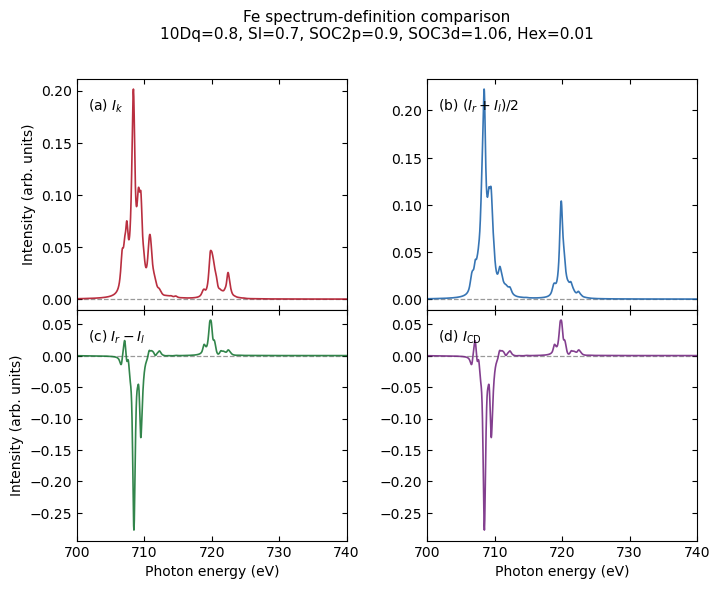


Saved files detected:
  figures/Figure_XAS_definition_comparison_Fe.pdf
  figures/Figure_XAS_definition_comparison_Fe.png


In [ ]:
#!/usr/bin/env python3

"""
Compare XAS/XMCD-related Quanty spectra for one Fe calculation.

This script is intended for execution from a Jupyter Notebook
located within the repository, typically in:

    notebooks/

The repository root is detected by searching upward for both:

    src/
    configs/

The script selects one complete Fe spectrum set containing:

    *_k.spec
    *_r.spec
    *_l.spec
    *_cd.spec

and compares:

    (a) k.spec
    (b) (r.spec + l.spec) / 2
    (c) r.spec - l.spec
    (d) cd.spec

The figure is saved to:

    figures/Figure_XAS_definition_comparison_Fe.png
    figures/Figure_XAS_definition_comparison_Fe.pdf

Absolute local paths are used internally but are not included
in normal console output or figure metadata.
"""

from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np

from matplotlib.gridspec import GridSpec


# ============================================================
# Settings
# ============================================================

figure_name = "Figure_XAS_definition_comparison_Fe"

system_name = "Fe_d6"

system_prefix = "Fe_L23_d6__"


# ============================================================
# Spectrum-selection settings
# ============================================================

# The first complete spectrum set matching these parameter
# values is selected.
#
# Use an empty dictionary to select the first complete set:
#
# fixed_parameters = {}
#
# To select a specific calculation:
#
# fixed_parameters = {
#     "10Dq": 1.20,
#     "Sl": 0.70,
#     "SOC2p": 0.90,
#     "SOC3d": 1.06,
#     "Hex": 0.01,
# }
fixed_parameters = {
    "Sl": 0.70,
    "SOC2p": 0.90,
    "SOC3d": 1.06,
    "Hex": 0.01,
}

parameter_tolerance = 1.0e-10


# ============================================================
# Spectrum-file settings
# ============================================================

spectrum_skip_header = 4

spectrum_energy_column = 0

spectrum_intensity_column = 2

energy_rtol = 1.0e-10

energy_atol = 1.0e-12


# ============================================================
# Plot settings
# ============================================================

x_range = (
    700.0,
    740.0,
)

output_dpi = 300

figure_size = (
    8.0,
    6.0,
)


# ============================================================
# Y-axis settings
# ============================================================

# Specify a tuple to use a common vertical range for all panels.
#
# Example:
#
# common_ylim = (-0.35, 0.30)
#
# Use None for automatic scaling.
common_ylim = None


# Individual y-axis limits override common_ylim.
#
# Example:
#
# panel_ylim = {
#     "k": (-0.01, 0.25),
#     "circular_average": (-0.01, 0.25),
#     "circular_difference": (-0.32, 0.12),
#     "cd": (-0.32, 0.12),
# }
panel_ylim = {
    "k": None,
    "circular_average": None,
    "circular_difference": None,
    "cd": None,
}


# ============================================================
# Panel appearance
# ============================================================

panel_labels = {
    "k": r"(a) $I_k$",

    "circular_average": (
        r"(b) $(I_r+I_l)/2$"
    ),

    "circular_difference": (
        r"(c) $I_r-I_l$"
    ),

    "cd": (
        r"(d) $I_{\mathrm{CD}}$"
    ),
}

panel_colors = {
    "k": "#B2182B",

    "circular_average": "#2166AC",

    "circular_difference": "#1B7837",

    "cd": "#762A83",
}


# ============================================================
# Repository-root detection
# ============================================================

def find_repository_root(
    start_directory=None,
):
    """
    Find the repository root by searching upward.

    The repository root is identified by the presence of both:

        src/
        configs/

    Parameters
    ----------
    start_directory : str, pathlib.Path, or None
        Starting directory. If None, the current working
        directory is used.

    Returns
    -------
    pathlib.Path
        Absolute repository-root path.
    """

    if start_directory is None:
        current_directory = Path.cwd().resolve()

    else:
        current_directory = (
            Path(start_directory)
            .expanduser()
            .resolve()
        )

    candidates = [
        current_directory,
        *current_directory.parents,
    ]

    for candidate in candidates:
        if (
            (candidate / "src").is_dir()
            and (candidate / "configs").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Repository root could not be found. "
        "Expected a parent directory containing "
        "both 'src' and 'configs'."
    )


repository_root = find_repository_root()

spectrum_directory = (
    repository_root
    / "quanty"
    / "runs"
    / system_name
    / "spec"
).resolve()

output_directory = (
    repository_root
    / "figures"
).resolve()

output_directory.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# Public path utility
# ============================================================

def repository_relative_path(
    path,
):
    """
    Convert a repository path to a relative POSIX path.

    Absolute paths are never returned.
    """

    path = (
        Path(path)
        .expanduser()
        .resolve(strict=False)
    )

    try:
        relative_path = path.relative_to(
            repository_root
        )

    except ValueError as exception:
        raise ValueError(
            "Path is outside the repository root"
        ) from exception

    return relative_path.as_posix()


# ============================================================
# Path report
# ============================================================

print(
    "Repository root   : <repository>"
)

print(
    "Spectrum directory:",
    repository_relative_path(
        spectrum_directory
    ),
)

print(
    "Output directory  :",
    repository_relative_path(
        output_directory
    ),
)


# ============================================================
# Spectrum loader
# ============================================================

def load_quanty_spec(
    filename,
):
    """
    Load energy and intensity columns from a Quanty spectrum.

    Parameters
    ----------
    filename : str or pathlib.Path
        Quanty spectrum file.

    Returns
    -------
    tuple of numpy.ndarray
        Energy and intensity arrays.
    """

    filename = Path(filename)

    if not filename.is_file():
        raise FileNotFoundError(
            "Spectrum file was not found: "
            f"{filename.name}"
        )

    data = np.genfromtxt(
        filename,
        comments="#",
        skip_header=spectrum_skip_header,
        dtype=np.float64,
    )

    if data.size == 0:
        raise ValueError(
            f"Empty spectrum: {filename.name}"
        )

    if data.ndim == 1:
        data = data.reshape(
            1,
            -1,
        )

    required_column = max(
        spectrum_energy_column,
        spectrum_intensity_column,
    )

    if (
        data.ndim != 2
        or data.shape[1] <= required_column
    ):
        raise ValueError(
            "Invalid spectrum layout in "
            f"{filename.name}: "
            f"shape={data.shape}"
        )

    energy = np.asarray(
        data[:, spectrum_energy_column],
        dtype=np.float64,
    )

    intensity = np.asarray(
        data[:, spectrum_intensity_column],
        dtype=np.float64,
    )

    finite_mask = (
        np.isfinite(energy)
        & np.isfinite(intensity)
    )

    energy = energy[
        finite_mask
    ]

    intensity = intensity[
        finite_mask
    ]

    if energy.size == 0:
        raise ValueError(
            "Spectrum contains no finite data points: "
            f"{filename.name}"
        )

    if np.any(
        np.diff(energy) <= 0.0
    ):
        raise ValueError(
            "Energy grid is not strictly increasing: "
            f"{filename.name}"
        )

    return (
        energy,
        intensity,
    )


# ============================================================
# Energy-grid validation
# ============================================================

def validate_same_energy_grid(
    reference_name,
    reference_energy,
    comparison_name,
    comparison_energy,
):
    """
    Validate that two spectra use equivalent energy grids.
    """

    reference_energy = np.asarray(
        reference_energy,
        dtype=np.float64,
    )

    comparison_energy = np.asarray(
        comparison_energy,
        dtype=np.float64,
    )

    if (
        reference_energy.shape
        != comparison_energy.shape
    ):
        raise ValueError(
            "Energy-grid length differs: "
            f"{reference_name}="
            f"{reference_energy.shape}, "
            f"{comparison_name}="
            f"{comparison_energy.shape}"
        )

    if not np.allclose(
        reference_energy,
        comparison_energy,
        rtol=energy_rtol,
        atol=energy_atol,
    ):
        maximum_difference = float(
            np.max(
                np.abs(
                    reference_energy
                    - comparison_energy
                )
            )
        )

        raise ValueError(
            "Energy grids differ between "
            f"{reference_name} and {comparison_name}. "
            "Maximum absolute difference: "
            f"{maximum_difference:.8e} eV"
        )


# ============================================================
# File-name parameter extraction
# ============================================================

def extract_parameter(
    filename,
    parameter_name,
):
    """
    Extract a floating-point parameter value from a file name.

    Supported examples include:

        Sl0.7000
        SOC2p0.9000
        SOC3d1.0600
        Hex0.010000
        Hex-0.010000
        10Dq1.2000
    """

    filename = Path(filename).name

    number_pattern = (
        r"([-+]?"
        r"(?:\d+(?:\.\d*)?|\.\d+)"
        r"(?:[eE][-+]?\d+)?)"
    )

    pattern = (
        re.escape(parameter_name)
        + number_pattern
    )

    match = re.search(
        pattern,
        filename,
    )

    if match is None:
        return None

    try:
        value = float(
            match.group(1)
        )

    except ValueError:
        return None

    if not np.isfinite(value):
        return None

    return value


def matches_fixed_parameters(
    filename,
):
    """
    Check whether a spectrum matches all fixed parameters.
    """

    for parameter_name, expected_value in (
        fixed_parameters.items()
    ):
        observed_value = extract_parameter(
            filename,
            parameter_name,
        )

        if observed_value is None:
            return False

        if not np.isclose(
            observed_value,
            expected_value,
            rtol=0.0,
            atol=parameter_tolerance,
        ):
            return False

    return True


def remove_exact_suffix(
    filename,
    suffix,
):
    """
    Remove an exact suffix from a file name.
    """

    filename = Path(filename).name

    if not filename.endswith(suffix):
        raise ValueError(
            f"{filename} does not end with {suffix}"
        )

    return filename[
        :-len(suffix)
    ]


# ============================================================
# Complete spectrum-set selection
# ============================================================

def select_complete_spectrum_set():
    """
    Select the first Fe calculation for which k, r, l, and cd
    spectrum files all exist.

    Complete sets are sorted by:

        10Dq
        Hex
        file name

    Returns
    -------
    tuple
        Selected record and number of matching complete sets.
    """

    if not spectrum_directory.is_dir():
        raise NotADirectoryError(
            "Spectrum directory was not found: "
            f"{repository_relative_path(spectrum_directory)}"
        )

    right_files = sorted(
        spectrum_directory.glob(
            "*_r.spec"
        )
    )

    complete_sets = []

    incomplete_count = 0

    for right_file in right_files:
        if not right_file.name.startswith(
            system_prefix
        ):
            continue

        if not matches_fixed_parameters(
            right_file.name
        ):
            continue

        base_name = remove_exact_suffix(
            right_file.name,
            "_r.spec",
        )

        spectrum_files = {
            "k": (
                spectrum_directory
                / f"{base_name}_k.spec"
            ),

            "r": (
                right_file
            ),

            "l": (
                spectrum_directory
                / f"{base_name}_l.spec"
            ),

            "cd": (
                spectrum_directory
                / f"{base_name}_cd.spec"
            ),
        }

        missing_files = [
            spectrum_type
            for spectrum_type, spectrum_file
            in spectrum_files.items()
            if not spectrum_file.is_file()
        ]

        if missing_files:
            incomplete_count += 1
            continue

        dq_value = extract_parameter(
            right_file.name,
            "10Dq",
        )

        hex_value = extract_parameter(
            right_file.name,
            "Hex",
        )

        complete_sets.append(
            {
                "base_name": base_name,

                "files": spectrum_files,

                "10Dq": dq_value,

                "Hex": hex_value,
            }
        )

    if not complete_sets:
        raise RuntimeError(
            "No complete Fe spectrum set matched "
            "the requested fixed parameters. "
            f"Incomplete matching sets: {incomplete_count}"
        )

    complete_sets = sorted(
        complete_sets,
        key=lambda record: (
            (
                float("inf")
                if record["10Dq"] is None
                else record["10Dq"]
            ),
            (
                float("inf")
                if record["Hex"] is None
                else record["Hex"]
            ),
            record["base_name"],
        ),
    )

    return (
        complete_sets[0],
        len(complete_sets),
    )


selected_record, matching_set_count = (
    select_complete_spectrum_set()
)

selected_files = selected_record[
    "files"
]


# ============================================================
# Selection report
# ============================================================

print()

print(
    "Matching complete sets:",
    matching_set_count,
)

print(
    "Selected prefix       :",
    selected_record[
        "base_name"
    ],
)

print(
    "Selected 10Dq         :",
    selected_record[
        "10Dq"
    ],
)

print(
    "Selected Hex          :",
    selected_record[
        "Hex"
    ],
)

print()

print(
    "Selected files"
)

print(
    "=" * 72
)

for spectrum_type, spectrum_file in (
    selected_files.items()
):
    print(
        f"{spectrum_type:4s}: "
        f"{repository_relative_path(spectrum_file)}"
    )


# ============================================================
# Load selected spectra
# ============================================================

energy_k, intensity_k = load_quanty_spec(
    selected_files[
        "k"
    ]
)

energy_r, intensity_r = load_quanty_spec(
    selected_files[
        "r"
    ]
)

energy_l, intensity_l = load_quanty_spec(
    selected_files[
        "l"
    ]
)

energy_cd, intensity_cd = load_quanty_spec(
    selected_files[
        "cd"
    ]
)


# ============================================================
# Validate energy grids
# ============================================================

validate_same_energy_grid(
    "k.spec",
    energy_k,
    "r.spec",
    energy_r,
)

validate_same_energy_grid(
    "k.spec",
    energy_k,
    "l.spec",
    energy_l,
)

validate_same_energy_grid(
    "k.spec",
    energy_k,
    "cd.spec",
    energy_cd,
)


# ============================================================
# Construct comparison spectra
# ============================================================

circular_average = (
    intensity_r
    + intensity_l
) / 2.0

circular_difference = (
    intensity_r
    - intensity_l
)

comparison_spectra = {
    "k": intensity_k,

    "circular_average": (
        circular_average
    ),

    "circular_difference": (
        circular_difference
    ),

    "cd": intensity_cd,
}

for spectrum_name, spectrum_values in (
    comparison_spectra.items()
):
    if not np.isfinite(
        spectrum_values
    ).all():
        raise ValueError(
            "Constructed spectrum contains "
            "non-finite values: "
            f"{spectrum_name}"
        )


# ============================================================
# Numerical comparison
# ============================================================

def difference_metrics(
    reference,
    comparison,
):
    """
    Calculate absolute and peak-normalized differences.

    Parameters
    ----------
    reference : array-like
        Reference spectrum.

    comparison : array-like
        Spectrum compared with the reference.

    Returns
    -------
    dict
        Absolute and normalized difference metrics.
    """

    reference = np.asarray(
        reference,
        dtype=np.float64,
    )

    comparison = np.asarray(
        comparison,
        dtype=np.float64,
    )

    if reference.shape != comparison.shape:
        raise ValueError(
            "Difference calculation requires "
            "equal array shapes"
        )

    difference = (
        comparison
        - reference
    )

    maximum_absolute_difference = float(
        np.max(
            np.abs(
                difference
            )
        )
    )

    rms_difference = float(
        np.sqrt(
            np.mean(
                difference ** 2
            )
        )
    )

    reference_peak = float(
        np.max(
            np.abs(
                reference
            )
        )
    )

    if reference_peak > 0.0:
        maximum_relative_to_peak = (
            maximum_absolute_difference
            / reference_peak
        )

        rms_relative_to_peak = (
            rms_difference
            / reference_peak
        )

    else:
        maximum_relative_to_peak = None
        rms_relative_to_peak = None

    return {
        "maximum_absolute_difference": (
            maximum_absolute_difference
        ),

        "rms_difference": (
            rms_difference
        ),

        "reference_peak": (
            reference_peak
        ),

        "maximum_relative_to_reference_peak": (
            maximum_relative_to_peak
        ),

        "rms_relative_to_reference_peak": (
            rms_relative_to_peak
        ),
    }


k_vs_circular_average = difference_metrics(
    reference=intensity_k,
    comparison=circular_average,
)

circular_difference_vs_cd = difference_metrics(
    reference=circular_difference,
    comparison=intensity_cd,
)


# ============================================================
# Numerical report
# ============================================================

print()

print(
    "Numerical comparison"
)

print(
    "=" * 72
)

print(
    "k.spec versus (r.spec + l.spec) / 2"
)

print(
    "  Maximum absolute difference : "
    f"{k_vs_circular_average['maximum_absolute_difference']:.8e}"
)

print(
    "  RMS difference              : "
    f"{k_vs_circular_average['rms_difference']:.8e}"
)

if (
    k_vs_circular_average[
        "maximum_relative_to_reference_peak"
    ]
    is not None
):
    print(
        "  Maximum difference / k peak: "
        f"{100.0 * k_vs_circular_average['maximum_relative_to_reference_peak']:.6f} %"
    )

    print(
        "  RMS difference / k peak    : "
        f"{100.0 * k_vs_circular_average['rms_relative_to_reference_peak']:.6f} %"
    )

print()

print(
    "cd.spec versus r.spec - l.spec"
)

print(
    "  Maximum absolute difference : "
    f"{circular_difference_vs_cd['maximum_absolute_difference']:.8e}"
)

print(
    "  RMS difference              : "
    f"{circular_difference_vs_cd['rms_difference']:.8e}"
)

if (
    circular_difference_vs_cd[
        "maximum_relative_to_reference_peak"
    ]
    is not None
):
    print(
        "  Maximum difference / circular-difference peak: "
        f"{100.0 * circular_difference_vs_cd['maximum_relative_to_reference_peak']:.6f} %"
    )

    print(
        "  RMS difference / circular-difference peak    : "
        f"{100.0 * circular_difference_vs_cd['rms_relative_to_reference_peak']:.6f} %"
    )


# ============================================================
# Create figure
# ============================================================

figure = plt.figure(
    figsize=figure_size
)

grid = GridSpec(
    2,
    2,
    figure=figure,
    hspace=0.00,
    wspace=0.30,
)

axes = np.empty(
    (
        2,
        2,
    ),
    dtype=object,
)

axes[
    0,
    0,
] = figure.add_subplot(
    grid[
        0,
        0,
    ]
)

axes[
    0,
    1,
] = figure.add_subplot(
    grid[
        0,
        1,
    ],
    sharex=axes[
        0,
        0,
    ],
)

axes[
    1,
    0,
] = figure.add_subplot(
    grid[
        1,
        0,
    ],
    sharex=axes[
        0,
        0,
    ],
)

axes[
    1,
    1,
] = figure.add_subplot(
    grid[
        1,
        1,
    ],
    sharex=axes[
        0,
        0,
    ],
)


# ============================================================
# Plot panels
# ============================================================

panel_layout = [
    (
        0,
        0,
        "k",
    ),

    (
        0,
        1,
        "circular_average",
    ),

    (
        1,
        0,
        "circular_difference",
    ),

    (
        1,
        1,
        "cd",
    ),
]

for (
    row,
    column,
    spectrum_name,
) in panel_layout:
    axis = axes[
        row,
        column,
    ]

    axis.plot(
        energy_k,
        comparison_spectra[
            spectrum_name
        ],
        color=panel_colors[
            spectrum_name
        ],
        linewidth=1.2,
        alpha=0.90,
    )

    axis.set_xlim(
        x_range
    )

    selected_ylim = panel_ylim[
        spectrum_name
    ]

    if selected_ylim is not None:
        axis.set_ylim(
            selected_ylim
        )

    elif common_ylim is not None:
        axis.set_ylim(
            common_ylim
        )

    axis.axhline(
        0.0,
        color="#999999",
        linewidth=0.9,
        linestyle="--",
        zorder=0,
    )

    axis.tick_params(
        direction="in",
        which="both",
        top=True,
        right=True,
    )

    axis.text(
        0.04,
        0.92,
        panel_labels[
            spectrum_name
        ],
        transform=axis.transAxes,
        verticalalignment="top",
    )

    if row == 0:
        axis.tick_params(
            labelbottom=False
        )


# ============================================================
# Axis labels
# ============================================================

axes[
    0,
    0,
].set_ylabel(
    "Intensity (arb. units)"
)

axes[
    1,
    0,
].set_ylabel(
    "Intensity (arb. units)"
)

axes[
    1,
    0,
].set_xlabel(
    "Photon energy (eV)"
)

axes[
    1,
    1,
].set_xlabel(
    "Photon energy (eV)"
)


# ============================================================
# Figure title
# ============================================================

parameter_text = []

for parameter_name in (
    "10Dq",
    "Sl",
    "SOC2p",
    "SOC3d",
    "Hex",
):
    parameter_value = extract_parameter(
        selected_files[
            "r"
        ].name,
        parameter_name,
    )

    if parameter_value is not None:
        parameter_text.append(
            f"{parameter_name}="
            f"{parameter_value:g}"
        )

figure.suptitle(
    "Fe spectrum-definition comparison\n"
    + ", ".join(
        parameter_text
    ),
    fontsize=11,
    y=0.995,
)


# ============================================================
# Output paths
# ============================================================

png_file = (
    output_directory
    / f"{figure_name}.png"
).resolve()

pdf_file = (
    output_directory
    / f"{figure_name}.pdf"
).resolve()


# ============================================================
# Save figure
# ============================================================

figure.canvas.draw()

png_metadata = {
    "Title": (
        "Fe spectrum-definition comparison"
    ),

    "Author": "",

    "Description": (
        "Comparison of Quanty k, circular-average, "
        "circular-difference, and CD spectra."
    ),

    "Software": "",
}

pdf_metadata = {
    "Title": (
        "Fe spectrum-definition comparison"
    ),

    "Author": "",

    "Subject": (
        "Comparison of Quanty spectrum definitions"
    ),

    "Keywords": (
        "XAS, XMCD, Quanty"
    ),

    "Creator": "",

    "Producer": "",
}

figure.savefig(
    png_file,
    dpi=output_dpi,
    format="png",
    bbox_inches="tight",
    facecolor="white",
    edgecolor="none",
    metadata=png_metadata,
)

figure.savefig(
    pdf_file,
    format="pdf",
    bbox_inches="tight",
    facecolor="white",
    edgecolor="none",
    metadata=pdf_metadata,
)


# ============================================================
# Verify saved files
# ============================================================

for output_file in (
    png_file,
    pdf_file,
):
    if not output_file.is_file():
        raise RuntimeError(
            "Figure was not saved: "
            f"{output_file.name}"
        )

    file_size = (
        output_file
        .stat()
        .st_size
    )

    if file_size <= 0:
        raise RuntimeError(
            "Saved figure is empty: "
            f"{output_file.name}"
        )

    print()

    print(
        "Saved:",
        repository_relative_path(
            output_file
        ),
    )

    print(
        "Size :",
        f"{file_size:,} bytes",
    )


# ============================================================
# Display and close
# ============================================================

plt.show()

plt.close(
    figure
)


# ============================================================
# Final public-safe report
# ============================================================

saved_files = sorted(
    output_directory.glob(
        f"{figure_name}.*"
    )
)

print()

print(
    "Saved files detected:"
)

for saved_file in saved_files:
    print(
        " ",
        repository_relative_path(
            saved_file
        ),
    )